In [1]:
import torch, torchaudio, random
import torch.nn as nn
import torch.optim as optim
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAMPLE_RATE, HOP_SECONDS = 44100, 0.010
HOP, N_FFT, N_MELS = int(HOP_SECONDS * SAMPLE_RATE), 2048, 128

class OnsetCRNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.mel   = torchaudio.transforms.MelSpectrogram(
            sample_rate=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP, n_mels=N_MELS)
        self.to_db = torchaudio.transforms.AmplitudeToDB()
        self.cnn = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(32), nn.MaxPool2d((2,1)),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(64), nn.MaxPool2d((2,1)),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.BatchNorm2d(128),
        )
        self.rnn = nn.GRU(128 * (N_MELS // 4), 128, num_layers=3, batch_first=True,
                          bidirectional=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.state_head, self.onset_head, self.offset_head = nn.Linear(256, 2), nn.Linear(256, 1), nn.Linear(256, 1)
    def forward(self, x):
        s = self.cnn(self.to_db(self.mel(x)))
        B, C, M, T = s.shape
        s, _ = self.rnn(s.reshape(B, C*M, T).transpose(1, 2))
        s = self.drop(s)
        return self.state_head(s), self.onset_head(s).squeeze(-1), self.offset_head(s).squeeze(-1)

weight_files = sorted(Path("/kaggle/input").rglob("biggerCRNN_ext4_seed*.pt"))
print("device:", device, "| weights:", [w.name for w in weight_files], "(expect 3)")

device: cuda | weights: ['biggerCRNN_ext4_seed0.pt', 'biggerCRNN_ext4_seed1.pt', 'biggerCRNN_ext4_seed2.pt'] (expect 3)


In [2]:
TONAS = Path("/kaggle/input/datasets/alirahmatpour/vocalset-onset/tonas_upload")
tonas = []
for wav in sorted(TONAS.rglob("*.wav")):
    notes = wav.parent / (wav.stem + ".notes.Corrected")
    if wav.name.startswith("._") or not notes.exists():
        continue
    wf, sr = torchaudio.load(str(wav))
    lines = notes.read_text(encoding="latin-1").strip().splitlines()[1:]
    on, off = [], []
    for ln in lines:
        p = [x.strip() for x in ln.split(",")]
        if len(p) >= 2:
            on.append(float(p[0])); off.append(float(p[0]) + float(p[1]))
    tonas.append({"name": wav.stem, "style": wav.parent.name, "wave": wf[0],
                  "onsets": np.array(on), "offsets": np.array(off)})
true_on = [(c["onsets"] / HOP_SECONDS).astype(int) for c in tonas]
print("TONAS clips:", len(tonas), "(expect 72)")

TONAS clips: 72 (expect 72)


In [3]:
V_ROOT  = Path("/kaggle/input/datasets/alirahmatpour/vocalset-onset")
V_ANNOT = V_ROOT / "annot_ext4_upload" / "annot_ext4_upload" / "annot"
V_AUDIO = V_ROOT / "kaggle_upload" / "kaggle_upload" / "audio"
TEST_SINGERS = {"female4", "male6"}
COLS = ["Sequence","Start","End","Duration","Type","AvgF0","MedF0","MinF0","MaxF0",
        "StdF0","AvgF0_inSTD","EstMIDI","GTNote","GTFreq","GTMIDI","Lyric",
        "GTDurName","GTDur","IntPrev","IntNext","Extra"]

def read_annot(csv_path):
    a = pd.read_csv(csv_path, skiprows=17, header=None, names=COLS)
    return a[["Start","End","Type"]].dropna(subset=["Start","End","Type"])

csv_lookup = {p.stem: p for p in V_ANNOT.rglob("*.csv")}

def load_vs(wav):
    wf, sr = torchaudio.load(str(wav))
    ann = read_annot(csv_lookup[wav.stem])
    if not len(ann) or abs(ann["End"].max() / (wf.shape[1] / sr) - 1.0) > 0.1:   # clean filter
        return None
    snd = ann[ann["Type"] == "Sound"]
    return {"wave": wf[0], "onsets": snd["Start"].values, "offsets": snd["End"].values}

all_wavs = [w for w in sorted(V_AUDIO.rglob("*.wav")) if w.stem in csv_lookup]
singer_of = lambda w: w.parts[w.parts.index("audio") + 1]

vs_test = [c for c in (load_vs(w) for w in all_wavs if singer_of(w) in TEST_SINGERS) if c]
vs_true = []
for c in vs_test:
    nfr = 1 + c["wave"].shape[0] // HOP
    vs_true.append(np.array(sorted({int(s / HOP_SECONDS) for s in c["onsets"] if int(s / HOP_SECONDS) < nfr})))

cands = [w for w in all_wavs if singer_of(w) not in TEST_SINGERS]
random.Random(0).shuffle(cands)
vs_train = []
for w in cands:
    if len(vs_train) >= 200: break
    c = load_vs(w)
    if c: vs_train.append(c)
print("VocalSet test:", len(vs_test), "(expect 252) | replay files:", len(vs_train), "(expect 200)")

VocalSet test: 252 (expect 252) | replay files: 200 (expect 200)


In [4]:
def pick_peaks(prob, thr, min_gap=3):
    peaks = []
    for i in range(len(prob)):
        if prob[i] < thr: continue
        lo, hi = max(0, i-1), min(len(prob), i+2)
        if prob[i] == prob[lo:hi].max() and (not peaks or i - peaks[-1] >= min_gap):
            peaks.append(i)
    return set(peaks)

def event_f1(probs, true_frames, thr, tol):
    tp = fp = fn = 0
    for prob, t_idx in zip(probs, true_frames):
        pred = pick_peaks(prob, thr); matched = set()
        for ti in t_idx:
            hit = next((pi for pi in pred if abs(pi - ti) <= tol and pi not in matched), None)
            if hit is not None: tp += 1; matched.add(hit)
            else: fn += 1
        fp += len(pred - matched)
    p = tp/(tp+fp) if tp+fp else 0.0; r = tp/(tp+fn) if tp+fn else 0.0
    return 2*p*r/(p+r) if p+r else 0.0

def probs_of(model, waves):
    model.eval()
    with torch.no_grad():
        return [torch.sigmoid(model(w.view(1,1,-1).to(device))[1])[0].cpu().numpy() for w in waves]

SOFT_WIDTH = 2
def make_targets(c):
    nfr = 1 + c["wave"].shape[0] // HOP
    st = np.zeros(nfr, np.int64); on_t = np.zeros(nfr, np.float32); off_t = np.zeros(nfr, np.float32)
    def bump(arr, center):
        for d in range(-SOFT_WIDTH, SOFT_WIDTH + 1):
            j = center + d
            if 0 <= j < nfr: arr[j] = max(arr[j], np.exp(-(d*d) / (2 * (SOFT_WIDTH/2)**2)))
    for a, b in zip(c["onsets"], c["offsets"]):
        fa, fb = int(a / HOP_SECONDS), int(b / HOP_SECONDS)
        st[fa:fb] = 1; bump(on_t, fa); bump(off_t, fb)
    return torch.tensor(st), torch.tensor(on_t), torch.tensor(off_t)

tonas_tg = [make_targets(c) for c in tonas]
vs_tg    = [make_targets(c) for c in vs_train]

def train_step(model, opt, ce, bce, wave, tg, crop=1500):
    st, on, off = tg
    nfr = len(st); s = np.random.randint(0, max(1, nfr - crop)); e = min(nfr, s + crop)
    ps, po, pf = model(wave[s*HOP : e*HOP].view(1, 1, -1).to(device))
    F = min(ps.shape[1], e - s)
    loss = (ce(ps[0, :F], st[s:s+F].to(device)) + bce(po[0, :F], on[s:s+F].to(device))
            + bce(pf[0, :F], off[s:s+F].to(device)))
    opt.zero_grad(); loss.backward(); opt.step()

def finetune_mix(wpath, train_idx, epochs=15, lr=1e-4, seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = OnsetCRNN().to(device)
    model.load_state_dict(torch.load(wpath, map_location=device))
    if not train_idx: return model
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    ce, bce = nn.CrossEntropyLoss(), nn.BCEWithLogitsLoss(pos_weight=torch.tensor(20.0, device=device))
    for ep in range(epochs):
        model.train()
        for i in random.sample(train_idx, len(train_idx)):
            train_step(model, opt, ce, bce, tonas[i]["wave"], tonas_tg[i])          # 1 TONAS clip
            j = random.randrange(len(vs_train))
            train_step(model, opt, ce, bce, vs_train[j]["wave"], vs_tg[j])          # 1 VocalSet clip
    return model

def make_split(split_seed):
    """Half of each style -> test, other half -> training pool (shuffled order)."""
    rng = random.Random(split_seed); by_style = {}
    for i, c in enumerate(tonas): by_style.setdefault(c["style"], []).append(i)
    test_idx, pool_idx = [], []
    for style, idxs in sorted(by_style.items()):
        idxs = idxs[:]; rng.shuffle(idxs); k = len(idxs) // 2
        test_idx += idxs[:k]; pool_idx += idxs[k:]
    rng.shuffle(pool_idx)
    return test_idx, pool_idx

In [5]:
SPLITS  = [0, 1]                               # split 0 = the one used last night
N_LIST  = [0, 1, 2, 3, 5, 8, 12, 18, 25, 36]
vs_waves = [c["wave"] for c in vs_test]
rows = []
for sp in SPLITS:
    test_idx, pool_idx = make_split(sp)
    t_waves = [tonas[i]["wave"] for i in test_idx]; t_true = [true_on[i] for i in test_idx]
    for N in N_LIST:
        for k, w in enumerate(weight_files):
            model = finetune_mix(w, pool_idx[:N], seed=k)
            tp, vp = probs_of(model, t_waves), probs_of(model, vs_waves)
            row = {"split": sp, "N": N, "seed": k,
                   "TONAS_20": event_f1(tp, t_true, 0.8, 2), "TONAS_50": event_f1(tp, t_true, 0.8, 5),
                   "VS_20": event_f1(vp, vs_true, 0.8, 2),   "VS_50": event_f1(vp, vs_true, 0.8, 5)}
            rows.append(row)
            print(f"split {sp} | N={N:2d} | seed {k} | TONAS {row['TONAS_20']:.3f}/{row['TONAS_50']:.3f}"
                  f" | VocalSet {row['VS_20']:.3f}/{row['VS_50']:.3f}")
            del model; torch.cuda.empty_cache()

curve = pd.DataFrame(rows)
curve.to_csv("/kaggle/working/tonas_learning_curve_2splits.csv", index=False)

split 0 | N= 0 | seed 0 | TONAS 0.130/0.424 | VocalSet 0.837/0.923
split 0 | N= 0 | seed 1 | TONAS 0.112/0.379 | VocalSet 0.847/0.933
split 0 | N= 0 | seed 2 | TONAS 0.180/0.461 | VocalSet 0.819/0.921
split 0 | N= 1 | seed 0 | TONAS 0.253/0.556 | VocalSet 0.815/0.921
split 0 | N= 1 | seed 1 | TONAS 0.260/0.569 | VocalSet 0.804/0.918
split 0 | N= 1 | seed 2 | TONAS 0.230/0.524 | VocalSet 0.808/0.907
split 0 | N= 2 | seed 0 | TONAS 0.270/0.563 | VocalSet 0.817/0.924
split 0 | N= 2 | seed 1 | TONAS 0.301/0.575 | VocalSet 0.804/0.924
split 0 | N= 2 | seed 2 | TONAS 0.263/0.535 | VocalSet 0.795/0.908
split 0 | N= 3 | seed 0 | TONAS 0.305/0.606 | VocalSet 0.811/0.921
split 0 | N= 3 | seed 1 | TONAS 0.335/0.604 | VocalSet 0.815/0.927
split 0 | N= 3 | seed 2 | TONAS 0.309/0.581 | VocalSet 0.803/0.912
split 0 | N= 5 | seed 0 | TONAS 0.329/0.609 | VocalSet 0.811/0.918
split 0 | N= 5 | seed 1 | TONAS 0.366/0.621 | VocalSet 0.809/0.921
split 0 | N= 5 | seed 2 | TONAS 0.351/0.612 | VocalSet 0.809/0

         TONAS_20        TONAS_50         VS_20         VS_50       
             mean    std     mean    std   mean    std   mean    std
split N                                                             
0     0     0.140  0.035    0.421  0.041  0.834  0.014  0.926  0.006
      1     0.248  0.016    0.550  0.023  0.809  0.006  0.915  0.007
      2     0.278  0.020    0.558  0.021  0.805  0.011  0.919  0.009
      3     0.316  0.017    0.597  0.014  0.810  0.006  0.920  0.008
      5     0.349  0.018    0.614  0.006  0.809  0.001  0.918  0.003
      8     0.400  0.022    0.669  0.015  0.808  0.010  0.915  0.008
      12    0.432  0.025    0.687  0.017  0.810  0.011  0.907  0.004
      18    0.442  0.029    0.711  0.006  0.811  0.009  0.912  0.012
      25    0.469  0.007    0.720  0.003  0.805  0.002  0.906  0.003
      36    0.485  0.014    0.745  0.004  0.803  0.014  0.908  0.010
1     0     0.145  0.041    0.412  0.044  0.834  0.014  0.926  0.006
      1     0.226  0.023    0.490 

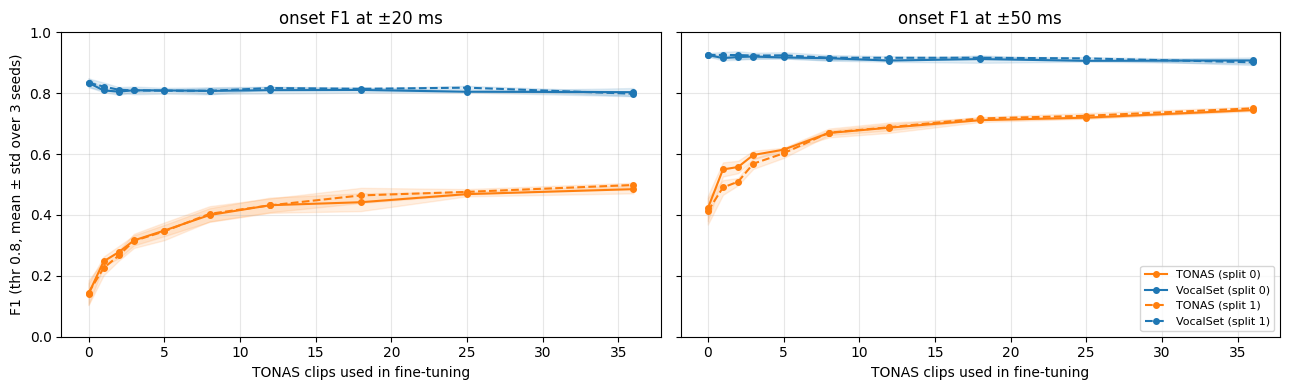

In [6]:
cols = ["TONAS_20", "TONAS_50", "VS_20", "VS_50"]
summary = curve.groupby(["split", "N"])[cols].agg(["mean", "std"]).round(3)
print(summary.to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, tol in zip(axes, ["20", "50"]):
    for sp, style in zip(SPLITS, ["-", "--"]):
        g = curve[curve.split == sp].groupby("N")
        for ds, color in [("TONAS", "tab:orange"), ("VS", "tab:blue")]:
            m, s = g[f"{ds}_{tol}"].mean(), g[f"{ds}_{tol}"].std()
            ax.plot(m.index, m.values, style, color=color, marker="o", ms=4,
                    label=f"{'TONAS' if ds=='TONAS' else 'VocalSet'} (split {sp})")
            ax.fill_between(m.index, m - s, m + s, color=color, alpha=0.12)
    ax.set_title(f"onset F1 at ±{tol} ms"); ax.set_xlabel("TONAS clips used in fine-tuning")
    ax.grid(alpha=0.3); ax.set_ylim(0, 1)
axes[0].set_ylabel("F1 (thr 0.8, mean ± std over 3 seeds)"); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("/kaggle/working/tonas_learning_curve_2splits.png", dpi=120); plt.show()